# Model comparison — batting/bowling contribution regressors

The production recommendation engine (`criiq_models.recommend.train`) uses a single
model family: `HistGradientBoostingRegressor`, chosen because it handles missing
values and pandas categorical columns natively with zero extra dependencies. This
notebook asks the obvious follow-up question: **how much does that choice actually
matter?** — by training several different model families on the *exact same*
leakage-safe training table and temporal holdout used by
`criiq_models/evaluate/backtest.py`, and comparing them head-to-head.

Models compared:
- **Linear Regression** / **Ridge** — the simplest possible baselines
- **Random Forest** — a bagged tree ensemble
- **HistGradientBoostingRegressor** — the current production model
- **XGBoost** — a widely-used gradient boosting library
- **LightGBM** — another widely-used gradient boosting library

Everything here reads real data from `data-collection`'s `criiq.db` and uses the
same `features/historical.py` point-in-time feature builder the production engine
trains on — no synthetic data, no shortcuts.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "criiq_models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from criiq_models.config import SETTINGS
from criiq_models.db import connect
from criiq_models.features.historical import build_training_table
from criiq_models.features.schema import CATEGORICAL_FEATURES, MODEL_FEATURES, NUMERIC_FEATURES, TARGETS

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = SETTINGS.random_state
print(f"format={SETTINGS.format} gender={SETTINGS.gender} random_state={RANDOM_STATE}")


format=T20 gender=female random_state=42


## 1. Load the leakage-safe training table

Same function the production `train`/`backtest` CLI commands use — every feature is
reconstructed strictly as-of *before* each match's date, so nothing here can leak a
match's own outcome into its own row. See `criiq_models/features/historical.py` for
exactly how (rolling form, expanding career-to-date, opponent/venue-to-date).


In [2]:
conn = connect()
table = build_training_table(conn, SETTINGS.format, SETTINGS.gender)
print(f"{len(table)} rows, {table['date'].min()} to {table['date'].max()}")
table[["date", "player_id", "role_bucket"] + TARGETS].head()


40955 rows, 2009-06-18 to 2026-06-15


,date,player_id,role_bucket,batting_wpa,bowling_wpa
0,2025-05-28,000efb34-8d8d-5ddc-b06b-327f2b628def,bowler,0.0,-0.12349
1,2025-05-29,000efb34-8d8d-5ddc-b06b-327f2b628def,bowler,0.0,0.07575
2,2025-05-29,000efb34-8d8d-5ddc-b06b-327f2b628def,bowler,0.0,0.07065
3,2025-07-19,000efb34-8d8d-5ddc-b06b-327f2b628def,bowler,0.0,0.06178
4,2025-07-20,000efb34-8d8d-5ddc-b06b-327f2b628def,bowler,0.0,-0.01496


## 2. Temporal holdout split

Identical methodology to `evaluate/backtest.py`: split by **match date**, never by
row. Rows from the same match are correlated (same opponent, same conditions), so a
random row-level split would leak information between train and test.


In [3]:
dates = pd.to_datetime(table["date"])
cutoff = dates.quantile(1 - SETTINGS.backtest_test_fraction)
train_df, test_df = table[dates < cutoff].copy(), table[dates >= cutoff].copy()

print(f"cutoff date: {cutoff.date()}")
print(f"train rows: {len(train_df)}   test rows: {len(test_df)}")


cutoff date: 2025-08-14
train rows: 32746   test rows: 8209


## 3. Two kinds of model need two kinds of input

`HistGradientBoostingRegressor`, `XGBoost` (with `enable_categorical=True`) and
`LightGBM` all handle missing numeric values *and* pandas `category`-dtype columns
natively — they can train directly on `MODEL_FEATURES` as-is.

`LinearRegression`, `Ridge` and `RandomForestRegressor` can't: linear models need
complete numeric input, and scikit-learn's `RandomForestRegressor` (unlike its
`HistGradientBoosting` sibling) doesn't accept `NaN` either. Both need median
imputation for numeric features and one-hot encoding for `role_bucket` — wrapped in
a `ColumnTransformer` so every model can still be called uniformly as
`model.fit(X_train, y_train)`.


In [4]:
def make_preprocessor():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])


def build_models():
    """Fresh instances every call -- trained once per target, never reused."""
    return {
        "Linear Regression": Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())]),
        "Ridge": Pipeline([("prep", make_preprocessor()), ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([("prep", make_preprocessor()), ("model", RandomForestRegressor(
            n_estimators=300, max_depth=10, min_samples_leaf=5,
            random_state=RANDOM_STATE, n_jobs=-1))]),
        "HistGradientBoosting (production)": HistGradientBoostingRegressor(
            categorical_features="from_dtype", random_state=RANDOM_STATE),
        "XGBoost": XGBRegressor(
            enable_categorical=True, tree_method="hist", n_estimators=300,
            max_depth=6, learning_rate=0.05, random_state=RANDOM_STATE),
        "LightGBM": LGBMRegressor(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            random_state=RANDOM_STATE, verbosity=-1),
    }


list(build_models().keys())


['Linear Regression',
 'Ridge',
 'Random Forest',
 'HistGradientBoosting (production)',
 'XGBoost',
 'LightGBM']

## 4. Train every model on every target

Two targets, exactly as in production: `bat_contribution_pct` and
`bowl_contribution_pct`, trained as **separate** regressions per model (a pure
bowler's ~0 batting contribution shouldn't drag down a blended label — see
`recommend/train.py`'s docstring for why). Rows with a missing target for that
discipline are dropped (a player who didn't bat/bowl in a match has nothing to
regress on for that axis) — identical to `evaluate/backtest.py`.


In [5]:
results = []
predictions = {}  # (target, model_name) -> (y_test array, y_pred array)
fitted_models = {}  # (target, model_name) -> fitted estimator, for feature importances

for target in TARGETS:
    train_rows = train_df.dropna(subset=[target])
    test_rows = test_df.dropna(subset=[target])
    X_train, y_train = train_rows[MODEL_FEATURES], train_rows[target]
    X_test, y_test = test_rows[MODEL_FEATURES], test_rows[target]

    baseline_pred = np.full(len(y_test), y_train.mean())
    results.append({
        "target": target, "model": "Mean-predictor baseline",
        "mae": mean_absolute_error(y_test, baseline_pred), "r2": 0.0,
        "corr": np.nan, "n_train": len(train_rows), "n_test": len(test_rows),
    })

    for name, model in build_models().items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        corr = float(np.corrcoef(y_pred, y_test)[0, 1]) if len(y_test) > 1 else np.nan
        results.append({
            "target": target, "model": name,
            "mae": mean_absolute_error(y_test, y_pred),
            "r2": r2_score(y_test, y_pred), "corr": corr,
            "n_train": len(train_rows), "n_test": len(test_rows),
        })
        predictions[(target, name)] = (y_test.to_numpy(), y_pred)
        fitted_models[(target, name)] = model

    print(f"done: {target} ({len(train_rows)} train / {len(test_rows)} test rows)")

results_df = pd.DataFrame(results)


done: batting_wpa (32526 train / 8155 test rows)


done: bowling_wpa (32526 train / 8155 test rows)


## 5. Results — MAE, R2, and correlation vs the mean-predictor baseline

In [6]:
for target in TARGETS:
    print(f"=== {target} ===")
    display(
        results_df[results_df["target"] == target]
        .drop(columns="target")
        .sort_values("mae")
        .reset_index(drop=True)
        .round(4)
    )


=== batting_wpa ===


,model,mae,r2,corr,n_train,n_test
0,Mean-predictor baseline,0.0808,0.0000,NaN,32526,8155
1,Random Forest,0.0820,0.0193,0.1398,32526,8155
2,HistGradientBoosting (production),0.0822,0.0140,0.1233,32526,8155
3,Ridge,0.0834,0.0104,0.1045,32526,8155
4,Linear Regression,0.0834,0.0104,0.1045,32526,8155
5,LightGBM,0.0836,0.0038,0.1132,32526,8155
6,XGBoost,0.0850,-0.0200,0.0924,32526,8155


=== bowling_wpa ===


,model,mae,r2,corr,n_train,n_test
0,Mean-predictor baseline,0.0680,0.0000,NaN,32526,8155
1,HistGradientBoosting (production),0.0693,0.0055,0.0789,32526,8155
2,Random Forest,0.0695,0.0075,0.0915,32526,8155
3,Ridge,0.0706,0.0081,0.0910,32526,8155
4,Linear Regression,0.0706,0.0081,0.0910,32526,8155
5,LightGBM,0.0714,-0.0110,0.0590,32526,8155
6,XGBoost,0.0720,-0.0244,0.0384,32526,8155


## 6. Visual comparison

Lower MAE is better; the dashed line marks the mean-predictor baseline (a model
that beats the baseline has *some* real signal, one that doesn't is worthless).


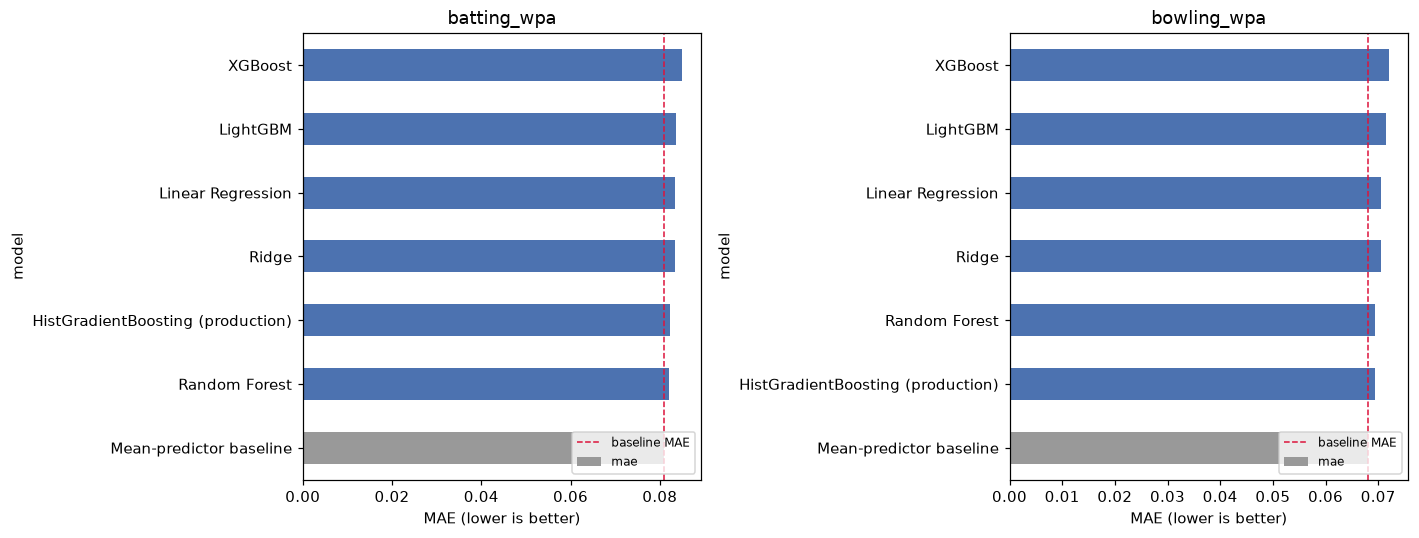

In [7]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 5), sharey=False)
for ax, target in zip(axes, TARGETS):
    sub = (results_df[results_df["target"] == target]
           .set_index("model")["mae"].sort_values())
    baseline_mae = sub["Mean-predictor baseline"]
    colors = ["#999999" if m == "Mean-predictor baseline" else "#4C72B0" for m in sub.index]
    sub.plot.barh(ax=ax, color=colors)
    ax.axvline(baseline_mae, color="crimson", linestyle="--", linewidth=1,
               label="baseline MAE")
    ax.set_xlabel("MAE (lower is better)")
    ax.set_title(target)
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


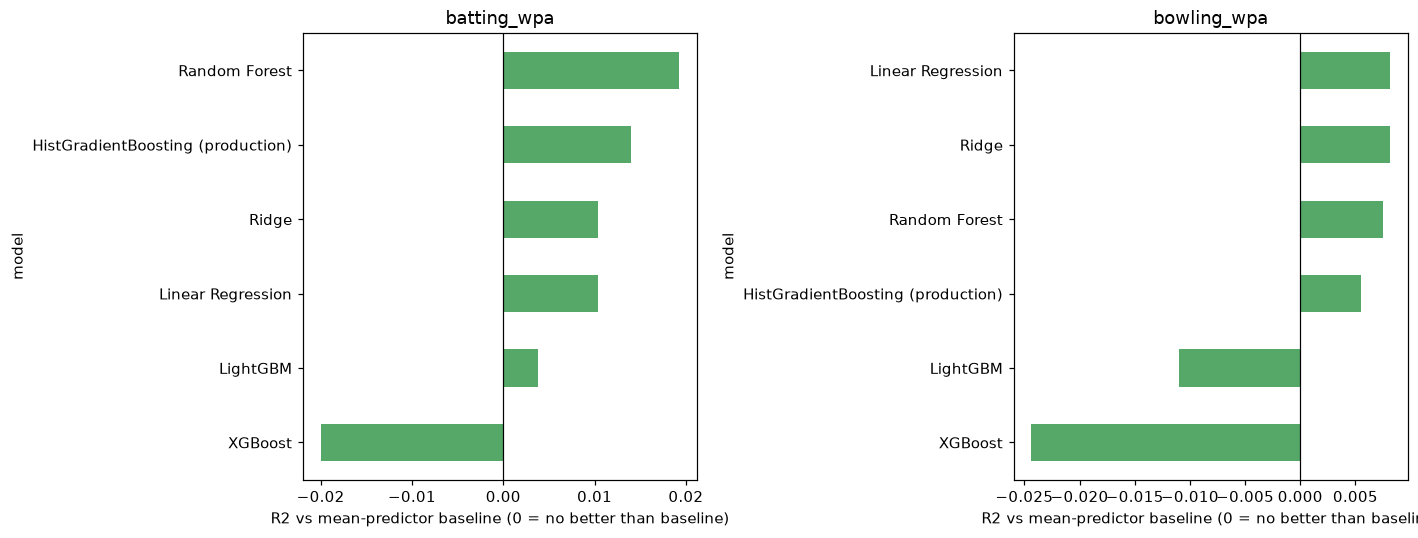

In [8]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 5), sharey=False)
for ax, target in zip(axes, TARGETS):
    sub = (results_df[(results_df["target"] == target)
                       & (results_df["model"] != "Mean-predictor baseline")]
           .set_index("model")["r2"].sort_values())
    sub.plot.barh(ax=ax, color="#55A868")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("R2 vs mean-predictor baseline (0 = no better than baseline)")
    ax.set_title(target)
plt.tight_layout()
plt.show()


## 7. Feature importance — do different model families agree on what matters?

Restricted to `Random Forest`, `XGBoost` and `LightGBM`: all three expose a native
`feature_importances_` on a directly comparable scale. `HistGradientBoostingRegressor`
doesn't expose this attribute at all (it would need permutation importance, a
separate and much slower computation) and linear models' coefficients aren't
comparable to tree split-gain importances, so both are left out of this specific
comparison rather than shown on a misleading shared axis.


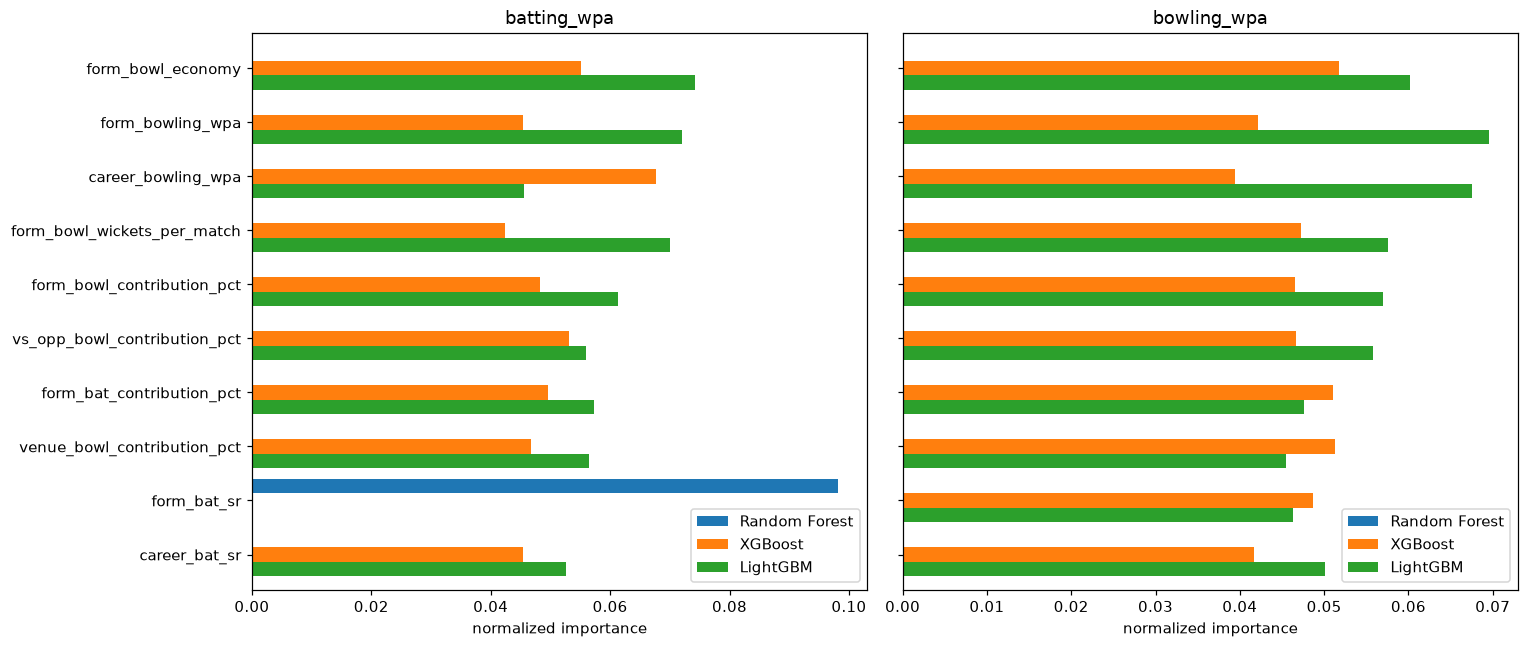

In [9]:
tree_models_for_importance = ["Random Forest", "XGBoost", "LightGBM"]

fig, axes = plt.subplots(1, len(TARGETS), figsize=(14, 6), sharey=True)
for ax, target in zip(axes, TARGETS):
    importances = {}
    for name in tree_models_for_importance:
        model = fitted_models[(target, name)]
        estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model
        if hasattr(model, "named_steps"):
            feature_names = model.named_steps["prep"].get_feature_names_out()
        else:
            feature_names = MODEL_FEATURES
        importances[name] = pd.Series(estimator.feature_importances_, index=feature_names)

    imp_df = pd.DataFrame(importances).fillna(0)
    # collapse one-hot role_bucket_* columns back into a single "role_bucket" row
    # so the RF importances line up with XGBoost/LightGBM's single categorical column
    role_cols = [c for c in imp_df.index if "role_bucket" in c]
    if role_cols:
        collapsed = imp_df.loc[role_cols].sum()
        imp_df = imp_df.drop(index=role_cols)
        imp_df.loc["role_bucket"] = collapsed
    imp_df = imp_df.div(imp_df.sum(axis=0), axis=1)  # normalize each model's importances to sum to 1

    top = imp_df.mean(axis=1).sort_values(ascending=False).head(10).index
    imp_df.loc[top].plot.barh(ax=ax, width=0.8)
    ax.set_title(target)
    ax.set_xlabel("normalized importance")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 8. Predicted vs. actual — the best model per target

The scatter should hug the diagonal for a well-calibrated model; given how noisy a
single match's contribution genuinely is (even great players have low-scoring
matches), a tight diagonal is *not* expected — the interesting signal is whether
there's a visible positive trend at all versus the baseline's flat horizontal line.


target
batting_wpa                        Random Forest
bowling_wpa    HistGradientBoosting (production)
Name: model, dtype: str


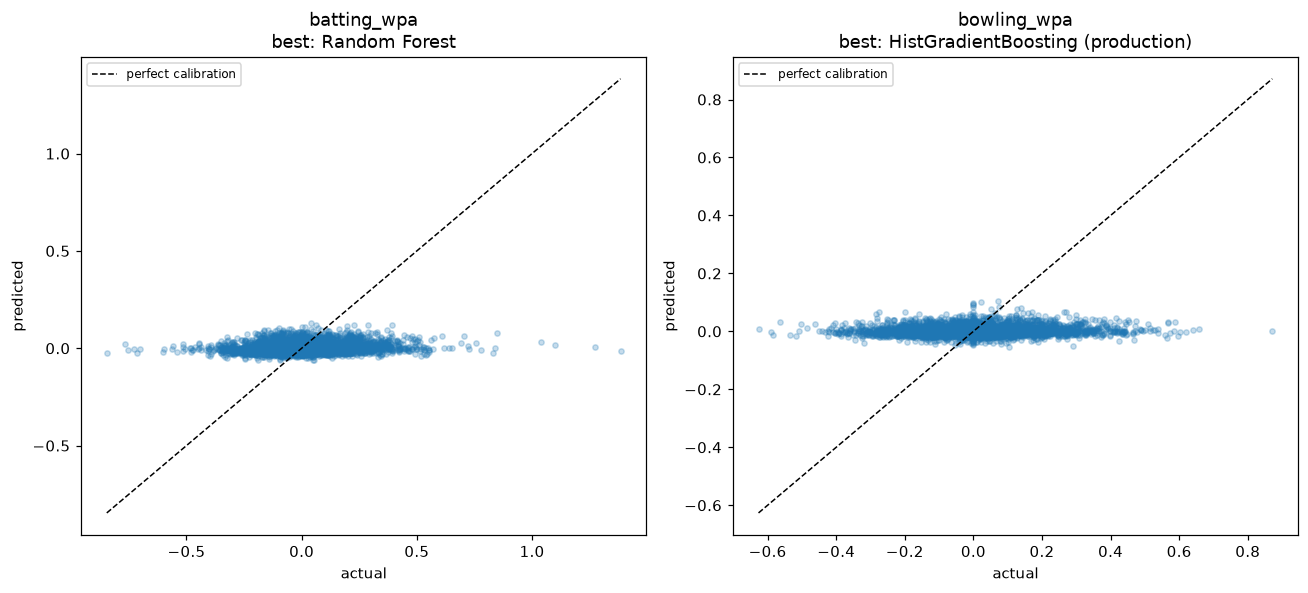

In [10]:
best_model_per_target = (
    results_df[results_df["model"] != "Mean-predictor baseline"]
    .sort_values("mae").groupby("target").first()["model"]
)
print(best_model_per_target)

fig, axes = plt.subplots(1, len(TARGETS), figsize=(12, 5.5))
for ax, target in zip(axes, TARGETS):
    name = best_model_per_target[target]
    y_test, y_pred = predictions[(target, name)]
    ax.scatter(y_test, y_pred, alpha=0.25, s=12)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1, label="perfect calibration")
    ax.set_xlabel("actual")
    ax.set_ylabel("predicted")
    ax.set_title(f"{target}\nbest: {name}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 9. Summary

In [11]:
print("Best model by MAE, per target (computed from the results above, not asserted):\n")
summary = (
    results_df[results_df["model"] != "Mean-predictor baseline"]
    .sort_values("mae").groupby("target").first()[["model", "mae", "r2", "corr"]]
)
baseline_mae_by_target = results_df[results_df["model"] == "Mean-predictor baseline"].set_index("target")["mae"]
summary["baseline_mae"] = baseline_mae_by_target
summary["improvement_over_baseline_pct"] = 100 * (1 - summary["mae"] / summary["baseline_mae"])
display(summary.round(4))

print(
    "\nRead this table, don't assume it: whichever row has the lowest MAE and the "
    "highest improvement-over-baseline is the empirically best model *for this "
    "training table, this holdout split, these hyperparameters* -- not a universal "
    "claim. Re-run this notebook after any change to features/historical.py or the "
    "training window and re-read the table again."
)


Best model by MAE, per target (computed from the results above, not asserted):



,model,mae,r2,corr,baseline_mae,improvement_over_baseline_pct
target,,,,,,
batting_wpa,Random Forest,0.0820,0.0193,0.1398,0.0808,-1.4016
bowling_wpa,HistGradientBoosting (production),0.0693,0.0055,0.0789,0.0680,-1.8963



Read this table, don't assume it: whichever row has the lowest MAE and the highest improvement-over-baseline is the empirically best model *for this training table, this holdout split, these hyperparameters* -- not a universal claim. Re-run this notebook after any change to features/historical.py or the training window and re-read the table again.
